# EDA và tiền xử lý GTSRB

**Phạm vi: Dữ liệu và tiền xử lý, không thay mô hình của nhóm.**

## 0. Bài toán & nguồn dữ liệu

**MỤC ĐÍCH:** Xác định đầu vào/đầu ra, nguồn dữ liệu, giả định và giới hạn trước khi phân tích.

- **Bài toán:** Phân loại ảnh biển báo giao thông, hỗ trợ nghiên cứu hệ thống hỗ trợ lái xe/xe tự lái. Đây không phải hệ thống đủ điều kiện triển khai an toàn trên xe.
- **Đầu vào:** Một ảnh đã định vị quanh một biển báo, kèm ROI khi có. **Đầu ra:** Một nhãn `ClassId` từ 0 đến 42 (43 lớp). Nhận dạng ở đây là **phân loại**, không phát hiện biển trong toàn cảnh đường phố.
- **Nguồn gốc:** GTSRB — German Traffic Sign Recognition Benchmark, Institut für Neuroinformatik, Ruhr-Universität Bochum; benchmark tại IJCNN 2011. Tham khảo J. Stallkamp và cộng sự, *The German Traffic Sign Recognition Benchmark: A multi-class classification competition*, DOI: [10.1109/IJCNN.2011.6033395](https://doi.org/10.1109/IJCNN.2011.6033395).
- **Trang dữ liệu gốc:** [GTSRB dataset](https://benchmark.ini.rub.de/gtsrb_dataset.html). **Bản phân phối PNG/CSV để tham khảo tải:** [GTSRB trên Kaggle](https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign). Repo cần `Train.csv`, `Test.csv`, `Meta.csv` và các thư mục ảnh tương ứng dưới `data/archive/`; bản gốc PPM không dùng trực tiếp với loader PNG/CSV này. Không có hồ sơ tải về để xác nhận chính xác nguồn của bản local.
- **Giấy phép: cần xác minh.** Không tìm thấy README/LICENSE trong bản dữ liệu local. Lần kiểm tra 2026-11-11 không truy cập được trang gốc và nội dung Kaggle trả về không đủ để xác nhận điều khoản. Người dùng cần kiểm tra giấy phép/điều kiện sử dụng trên trang tải của đúng bản dữ liệu; không suy ra giấy phép từ việc tải được công khai.
- **Giả định:** Mỗi ảnh có một biển đã định vị, ROI và nhãn đúng; train/test giữ theo CSV chính thức của bản phân phối.
- **Giới hạn:** Biển Đức, không bảo đảm tổng quát sang biển Việt Nam; mất cân bằng lớp; ảnh liên tiếp cùng track rất giống nhau; thay đổi ánh sáng, mờ và độ phân giải thấp. Không dùng kết quả ở đây làm cam kết hiệu năng ngoài thực địa.

**NHẬN XÉT:** Metadata local có **39.209 train / 12.630 test / 43 lớp** (kiểm chứng ở mục 1). Nguồn gốc benchmark đã nêu rõ, nhưng nguồn của bản local và giấy phép vẫn **cần người dùng xác minh**, không tự gán một giấy phép. Ablation tiền xử lý bổ sung nằm trong [02_preprocessing_ablation.ipynb](02_preprocessing_ablation.ipynb).

### Chuẩn bị môi trường

Notebook dùng toàn bộ metadata train/test chính thức; chỉ đọc mẫu ảnh cho thống kê
pixel, dùng cache ở thí nghiệm KNN và kiểm tra cuối. Mỗi mục gồm **MỤC ĐÍCH → mã →
NHẬN XÉT**. Các nhận xét số học được đối chiếu với kết quả lần chạy lưu trong notebook.

**MỤC ĐÍCH:** Tìm gốc dự án từ thư mục hiện tại, dùng cấu hình chung,
đặt seed `RANDOM_STATE`, lưu PNG 150 dpi và bảng CSV để kiểm tra số liệu.
Chọn kernel của môi trường đã cài `requirements.txt`, rồi **Restart & Run All**.
Không chạy notebook từ bên trong thư mục dữ liệu tải về.

In [1]:
from collections import Counter
from pathlib import Path
import gc
import json
import platform
import sys
import textwrap
import time

import cv2
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
from threadpoolctl import threadpool_limits

ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "src" / "config.py").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Hãy chạy notebook từ gốc dự án hoặc notebooks/")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import (
    DATA_DIR,
    DATA_ARCHIVE_DIR,
    FIGURES_DIR,
    IMAGE_SIZE,
    RANDOM_STATE,
)
from src.preprocessing import (
    CLASS_NAMES,
    ROI_COLUMNS,
    augment_image,
    crop_roi,
    load_and_preprocess,
    load_image,
    read_rgb,
    to_grayscale,
)

ARCHIVE = ROOT / DATA_ARCHIVE_DIR
FIGURES = ROOT / FIGURES_DIR
TABLES = ROOT / "report" / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

# PNG dành cho báo cáo/in nên dùng nền sáng cố định, không đảo màu ảnh.
# Ba màu đã được kiểm tra CVD; mọi biểu đồ có bảng số và nhãn đi kèm.
COLORS = {"Train": "#2a78d6", "Test": "#eb6834", "accent": "#1baf7a"}
INK, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e1e0d9"
PRINT_TEXTURE = False  # Bật khi cần bản in đen trắng.
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "text.color": INK,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.edgecolor": GRID,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "legend.frameon": False,
    }
)

summary = {"random_state": RANDOM_STATE, "python": platform.python_version()}
saved_figures = []


def save_figure(fig: plt.Figure, name: str) -> None:
    """Lưu PNG 150 dpi, hiển thị rồi giải phóng figure."""
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight")
    saved_figures.append(name)
    plt.show()
    plt.close(fig)


def save_table(frame: pd.DataFrame, name: str) -> None:
    """Xuất bảng UTF-8 để đối chiếu biểu đồ và dùng trong báo cáo."""
    frame.to_csv(TABLES / name, index=True, encoding="utf-8-sig")


def stratified_indices(labels: np.ndarray, size: int) -> np.ndarray:
    """Lấy mẫu trong MỘT tập có sẵn, không chia lại train/test chính thức."""
    if size >= len(labels):
        return np.arange(len(labels))
    sampler = StratifiedShuffleSplit(
        n_splits=1, train_size=size, random_state=RANDOM_STATE
    )
    selected, _ = next(sampler.split(np.zeros(len(labels)), labels))
    return selected


print("Seed:", RANDOM_STATE, "| Kích thước:", IMAGE_SIZE)
print("Python:", platform.python_version(), "| OpenCV:", cv2.__version__)

Seed: 42 | Kích thước: (32, 32)
Python: 3.13.2 | OpenCV: 5.0.0


**NHẬN XÉT:** Thống nhất seed từ config và đầu ra 32×32 RGB. PNG có nền sáng cố định
để chèn LaTeX; bảng CSV trong `report/tables/` là kênh đọc số không phụ thuộc màu.
Notebook không thay đổi thư mục làm việc và không thực thi file trong `data/archive/`.

## 1. Cấu trúc và tính toàn vẹn dữ liệu
**MỤC ĐÍCH:** Kiểm tra số mẫu/lớp, schema, NaN, trùng dòng/Path và sự tồn tại của
**tất cả** đường dẫn trong ba CSV. Tách ảnh mẫu chuẩn Meta khỏi dữ liệu huấn luyện.
Không duyệt file rác `.~lock.*.ods#` làm ảnh.

In [2]:
frames = {
    name: pd.read_csv(ARCHIVE / f"{name}.csv")
    for name in ("Train", "Test", "Meta")
}
train_df, test_df, meta_df = (
    frames[name] for name in ("Train", "Test", "Meta")
)
print("data/archive/")
for entry in sorted(ARCHIVE.iterdir()):
    if not entry.name.startswith(".~lock."):
        print("  ", entry.name + ("/" if entry.is_dir() else ""))

integrity_rows = []
for name, frame in frames.items():
    print(f"\n=== {name} ===")
    frame.info()
    display(frame.head())
    display(frame.isna().sum().rename("Số NaN").to_frame())
    missing_paths = [
        path for path in frame["Path"] if not (ARCHIVE / path).is_file()
    ]
    integrity_rows.append(
        {
            "Tập": name,
            "Số dòng": len(frame),
            "Số lớp": frame.ClassId.nunique(),
            "NaN": int(frame.isna().sum().sum()),
            "Dòng trùng": int(frame.duplicated().sum()),
            "Path trùng": int(frame.Path.duplicated().sum()),
            "Path thiếu": len(missing_paths),
        }
    )
    assert not missing_paths, f"Thiếu ảnh {name}: {missing_paths[:5]}"
    assert set(frame.ClassId) == set(range(43))

integrity = pd.DataFrame(integrity_rows).set_index("Tập")
display(integrity)
assert not set(train_df.Path) & set(test_df.Path)
assert not meta_df.ClassId.duplicated().any()
print("Meta có NaN:")
display(meta_df.loc[meta_df.isna().any(axis=1)])
# ClassId + số track trong tên ảnh là một nhóm, không chỉ số track riêng lẻ.
tracks = train_df.Path.map(
    lambda path: "_".join(Path(path).stem.split("_")[:2])
)
track_sizes = tracks.value_counts()
print("Số track train:", len(track_sizes), "| trung vị:", track_sizes.median())
summary["integrity"] = integrity.to_dict(orient="index")
summary["tracks"] = {
    "count": len(track_sizes),
    "min": int(track_sizes.min()),
    "median": float(track_sizes.median()),
    "max": int(track_sizes.max()),
}
save_table(integrity, "eda_integrity.csv")

data/archive/
   Meta/
   Meta.csv
   Test/
   Test.csv
   Train/
   Train.csv

=== Train ===


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39209 entries, 0 to 39208
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Width    39209 non-null  int64 
 1   Height   39209 non-null  int64 
 2   Roi.X1   39209 non-null  int64 
 3   Roi.Y1   39209 non-null  int64 
 4   Roi.X2   39209 non-null  int64 
 5   Roi.Y2   39209 non-null  int64 
 6   ClassId  39209 non-null  int64 
 7   Path     39209 non-null  object
dtypes: int64(7), object(1)
memory usage: 2.4+ MB


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


,Số NaN
Width,0
Height,0
Roi.X1,0
Roi.Y1,0
Roi.X2,0
Roi.Y2,0
ClassId,0
Path,0



=== Test ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12630 entries, 0 to 12629
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Width    12630 non-null  int64 
 1   Height   12630 non-null  int64 
 2   Roi.X1   12630 non-null  int64 
 3   Roi.Y1   12630 non-null  int64 
 4   Roi.X2   12630 non-null  int64 
 5   Roi.Y2   12630 non-null  int64 
 6   ClassId  12630 non-null  int64 
 7   Path     12630 non-null  object
dtypes: int64(7), object(1)
memory usage: 789.5+ KB


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png


... (4 outputs left out)

,Số dòng,Số lớp,NaN,Dòng trùng,Path trùng,Path thiếu
Tập,,,,,,
Train,39209,43,0,0,0,0
Test,12630,43,0,0,0,0
Meta,43,43,1,0,0,0


Meta có NaN:


,Path,ClassId,ShapeId,ColorId,SignId
24,Meta/30.png,30,0,0,NaN


Số track train: 1307 | trung vị: 30.0


**NHẬN XÉT:** Có **39.209 ảnh train, 12.630 ảnh test, 43 lớp** và 43 ảnh Meta.
Hai CSV train/test không có NaN hay dòng/Path trùng; mọi đường dẫn đều tồn tại.
`Meta.csv` có **1 NaN tại SignId của ClassId=30** (chuỗi `None`), không ảnh hưởng
đến ClassId/ColorId/ShapeId nên không loại lớp này. Không suy đoán SignId còn thiếu.

Train có **1.307 track**, trung vị **30 ảnh/track**: 1.306 track có 30 ảnh và
track `00033_00019` có 29 ảnh. Vì vậy 39.209 thay vì 39.210 là số dòng thực tế,
không tự bổ sung ảnh hay nhãn. Cần dùng cả ClassId lẫn TrackId khi chia fold.
Kiểm tra Path không chứng minh không có ảnh trùng nội dung; chưa băm toàn bộ ảnh.

## 2. Phân phối nhãn và mất cân bằng
**MỤC ĐÍCH:** So sánh train/test theo ClassId trên cùng thang số lượng; chỉ tô nổi
các lớp cực trị, có nhãn chữ và bảng đi kèm. Tính min/max/mean/median, tỉ lệ max/min
và top 5 lớp ít/nhiều để giải thích vì sao Accuracy không đủ.

,Train,Test
min,210.000,60.000
max,2250.000,750.000
mean,911.837,293.721
median,600.000,180.000
max/min,10.714,12.500


Train — 5 lớp ít nhất:


,Train,Test,Tên lớp
ClassId,,,
0,210,60,Speed limit 20
19,210,60,Dangerous curve left
37,210,60,Go straight or left
27,240,60,Pedestrians
32,240,60,End of all speed and passing limits


Train — 5 lớp nhiều nhất:


,Train,Test,Tên lớp
ClassId,,,
2,2250,750,Speed limit 50
1,2220,720,Speed limit 30
13,2160,720,Yield
12,2100,690,Priority road
38,2070,690,Keep right


Test — 5 lớp ít nhất:


,Train,Test,Tên lớp
ClassId,,,
0,210,60,Speed limit 20
19,210,60,Dangerous curve left
27,240,60,Pedestrians
32,240,60,End of all speed and passing limits
37,210,60,Go straight or left


Test — 5 lớp nhiều nhất:


,Train,Test,Tên lớp
ClassId,,,
2,2250,750,Speed limit 50
1,2220,720,Speed limit 30
13,2160,720,Yield
12,2100,690,Priority road
38,2070,690,Keep right


,Train,Test,Tên lớp
ClassId,,,
0,210,60,Speed limit 20
1,2220,720,Speed limit 30
2,2250,750,Speed limit 50
3,1410,450,Speed limit 60
4,1980,660,Speed limit 70
5,1860,630,Speed limit 80
6,420,150,End of speed limit 80
7,1440,450,Speed limit 100
8,1410,450,Speed limit 120


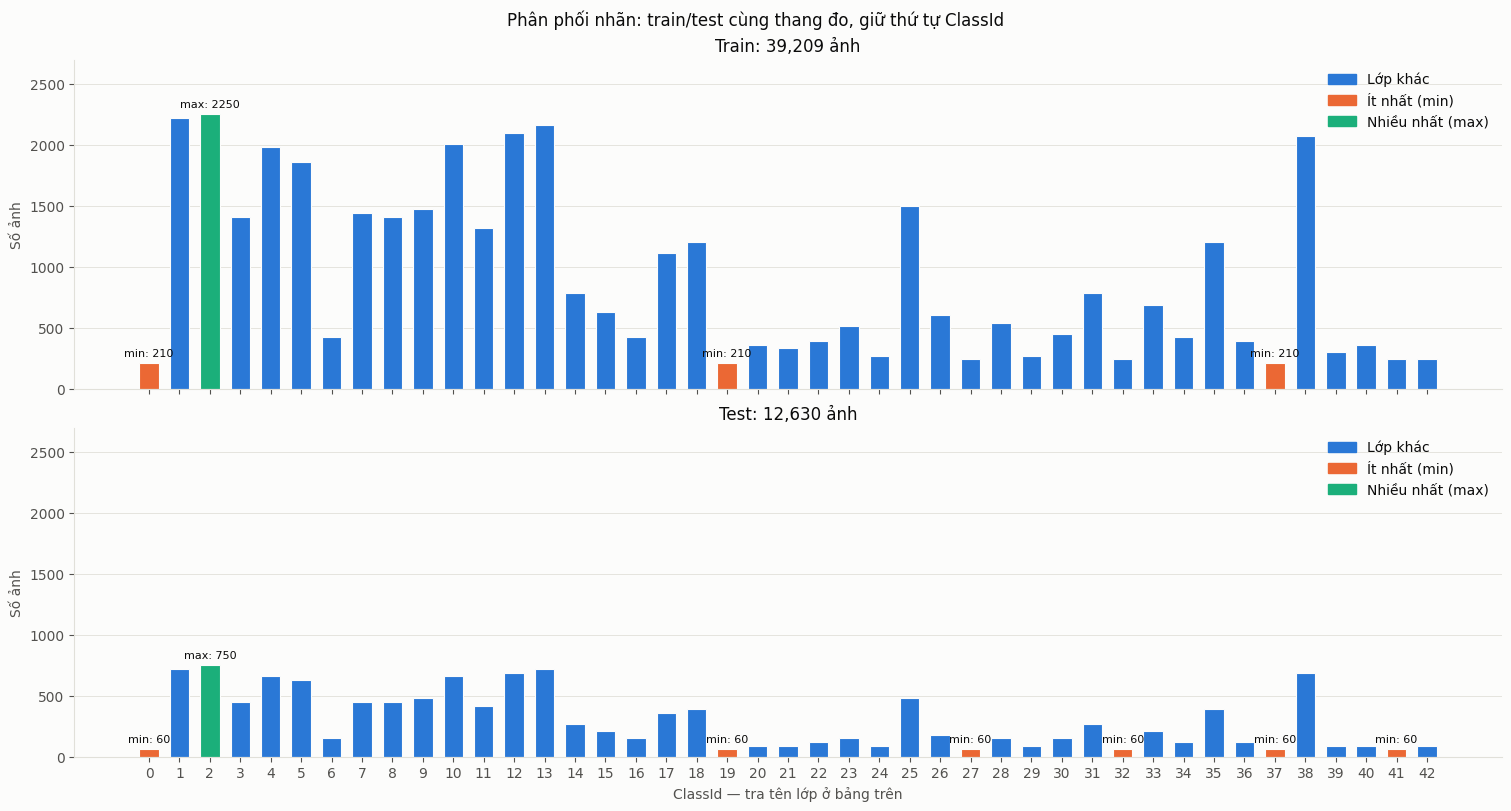

In [3]:
counts = pd.DataFrame(
    {
        name: frame.ClassId.value_counts().reindex(range(43), fill_value=0)
        for name, frame in (("Train", train_df), ("Test", test_df))
    }
).sort_index()
counts.index.name = "ClassId"
counts["Tên lớp"] = CLASS_NAMES
label_stats = counts[["Train", "Test"]].agg(["min", "max", "mean", "median"])
label_stats.loc["max/min"] = label_stats.loc["max"] / label_stats.loc["min"]
display(label_stats.round(3))
for split in ("Train", "Test"):
    print(f"{split} — 5 lớp ít nhất:")
    display(counts.sort_values([split], kind="stable").head(5))
    print(f"{split} — 5 lớp nhiều nhất:")
    display(
        counts.sort_values([split], ascending=False, kind="stable").head(5)
    )
display(counts)

fig, axes = plt.subplots(
    2, 1, figsize=(15, 8), sharex=True, sharey=True, layout="constrained"
)
for ax, split in zip(axes, ("Train", "Test")):
    values = counts[split]
    fills = [
        (
            COLORS["Test"]
            if value == values.min()
            else COLORS["accent"] if value == values.max() else COLORS["Train"]
        )
        for value in values
    ]
    bars = ax.bar(
        counts.index,
        values,
        width=0.64,
        color=fills,
        edgecolor=SURFACE,
        linewidth=0.8,
        hatch="/" if PRINT_TEXTURE else None,
    )
    for class_id, value in values.items():
        if value in (values.min(), values.max()):
            label = "min" if value == values.min() else "max"
            ax.annotate(
                f"{label}: {value}",
                (class_id, value),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                fontsize=8,
            )
    ax.set(title=f"{split}: {len(frames[split]):,} ảnh", ylabel="Số ảnh")
    ax.grid(axis="y")
    ax.set_ylim(0, counts.Train.max() * 1.2)
    ax.legend(
        handles=[
            Patch(color=COLORS["Train"], label="Lớp khác"),
            Patch(color=COLORS["Test"], label="Ít nhất (min)"),
            Patch(color=COLORS["accent"], label="Nhiều nhất (max)"),
        ],
        loc="upper right",
    )
axes[-1].set(xticks=range(43), xlabel="ClassId — tra tên lớp ở bảng trên")
fig.suptitle("Phân phối nhãn: train/test cùng thang đo, giữ thứ tự ClassId")
save_figure(fig, "eda_label_distribution.png")
save_table(counts, "eda_label_counts.csv")
save_table(label_stats, "eda_label_statistics.csv")
summary["labels"] = {
    split: {
        "min": int(counts[split].min()),
        "max": int(counts[split].max()),
        "ratio": float(label_stats.loc["max/min", split]),
        "min_classes": counts.index[
            counts[split].eq(counts[split].min())
        ].tolist(),
        "max_classes": counts.index[
            counts[split].eq(counts[split].max())
        ].tolist(),
    }
    for split in ("Train", "Test")
}

**NHẬN XÉT:** Train có **210–2.250 ảnh/lớp**, chênh **10,71 lần**.
Ba lớp ít nhất cùng 210 ảnh: **0 (Speed limit 20), 19 (Dangerous curve left),
37 (Go straight or left)**. Lớp nhiều nhất là **2 (Speed limit 50), 2.250 ảnh**.
Test có 60–750 ảnh/lớp, chênh **12,5 lần**. Accuracy ưu ái các lớp phổ biến;
**Macro-F1** tính F1 từng lớp rồi lấy trung bình ngang trọng số nên cần báo cáo
song song, cùng recall từng lớp. Không cân bằng lại test để làm đẹp điểm số.

## 3. Kích thước và kênh màu
**MỤC ĐÍCH:** Lấy Width/Height trực tiếp từ CSV, không giải mã 51.839 ảnh chỉ để
đo kích thước. Báo cáo hai định nghĩa rõ ràng: **cả hai chiều <32** và **ít nhất
một chiều <32**. Kiểm tra kênh/dtype gốc trên mẫu 500 ảnh train/test.

Tập,Train,Test
Width_min,25.000000,25.000000
Width_median,43.000000,43.000000
Width_max,243.000000,266.000000
Height_min,25.000000,25.000000
Height_median,43.000000,43.000000
Height_max,225.000000,232.000000
Tỉ lệ W/H min,0.368132,0.392857
Tỉ lệ W/H median,1.000000,1.000000
Tỉ lệ W/H max,1.417808,1.437500
Cả hai chiều <32,4766.000000,1632.000000


Width             Height            
          min median  max    min median  max
ClassId                                     
0          27   45.5  144     26   45.0  148
1          25   47.0  164     25   48.0  170
2          25   40.0  171     25   40.0  171
3          25   39.0  151     25   39.0  156
4          25   40.0  148     25   41.0  152
5          25   38.0  161     25   38.0  168
6          25   36.0   98     26   38.0  108
7          25   39.0  176     25   39.0  175
8          25   39.0  147     25   39.0  148
9          25   42.0  170     26   42.0  171
10         25   39.0  143     25   39.0  154
11         25   54.0  216     25   51.0  203
12         25   47.0  196     25   47.0  196
13         25   51.0  224     25   49.0  201
14         25   55.0  224     26   56.0  219
15         26   40.0  125     25   44.0  164
16         26   44.5  200     26   46.0  195
17         25   34.0  120     25   37.0  127
18         26   54.0  205     26   52.0  192
19         30   55.0  169     28   50.5  147
20         26   41.0  166     25   40.0  152
21         29   47.0  200     27   44.0  178
22         27   45.0  182     25   42.0  171
23         26   55.0  226     25   51.0  213
24         25   54.0  191     25   53.0  168
25         26   54.0  243     25   51.0  225
26         27   46.0  208     26   42.0  191
27         28   50.0  181     25   47.5  165
28         28   52.0  176     26   49.0  161
29         27   49.0  170     28   48.0  182
30         27   47.0  221     25   43.0  192
31         26   47.5  191     25   44.0  176
32         25   35.0  135     26   35.0  133
33         26   43.0  161     26   45.0  166
34         26   40.0  136     27   41.0  149
35         25   40.0  155     25   41.0  151
36         25   40.0  124     25   40.0  122
37         26   44.0  136     26   45.0  134
38         25   40.0  140     25   41.0  147
39         25   47.0  188     25   48.0  193
40         25   50.0  177     25   50.5  173
41         26   40.0  131     25   41.0  144
42         26   37.0  124     25   37.0  118

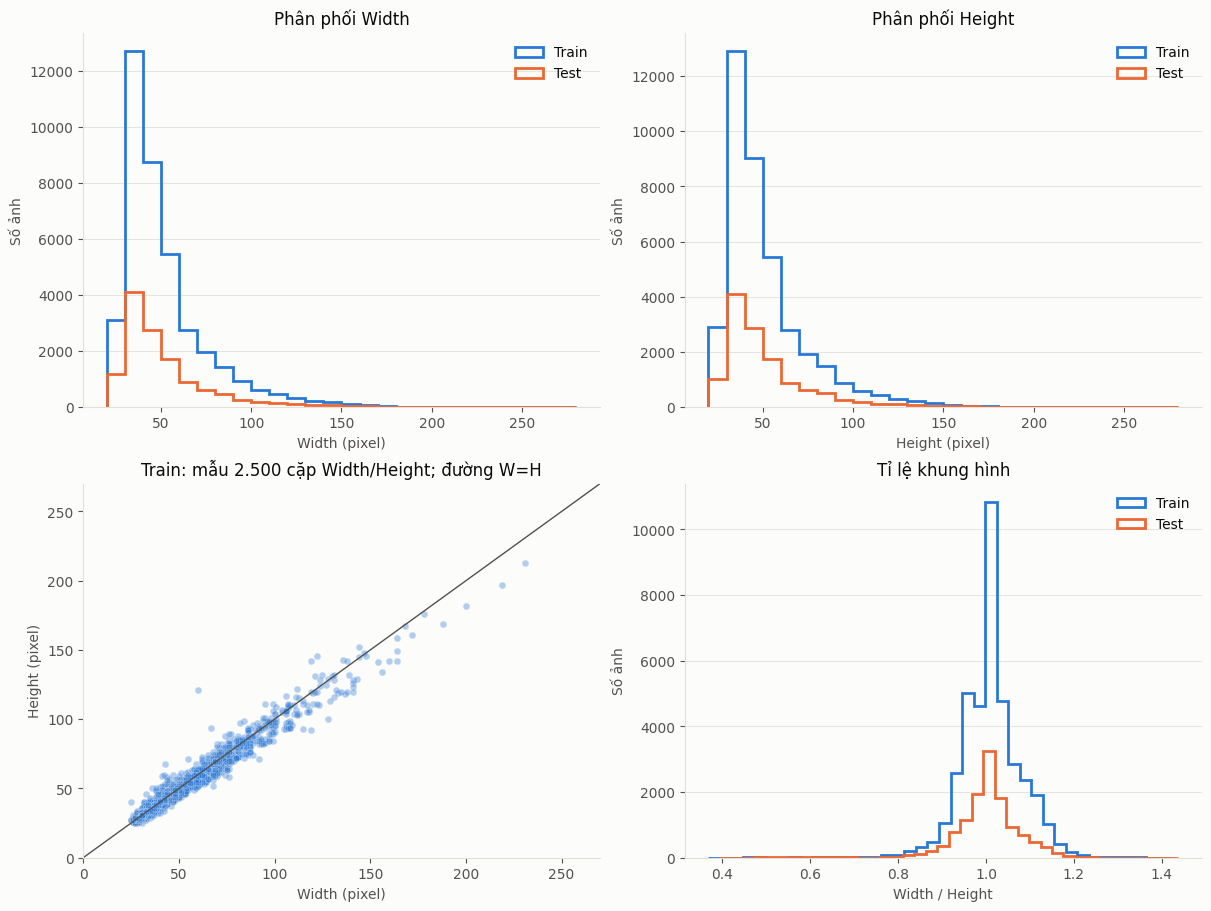

,Số kênh,dtype,Số ảnh
0,3,uint8,500


In [4]:
size_rows = []
for split in ("Train", "Test"):
    frame = frames[split]
    ratio = frame.Width / frame.Height
    row = {"Tập": split}
    for field in ("Width", "Height"):
        for statistic in ("min", "median", "max"):
            row[f"{field}_{statistic}"] = float(
                getattr(frame[field], statistic)()
            )
    row.update(
        {
            "Tỉ lệ W/H min": ratio.min(),
            "Tỉ lệ W/H median": ratio.median(),
            "Tỉ lệ W/H max": ratio.max(),
            "Cả hai chiều <32": int(
                ((frame.Width < 32) & (frame.Height < 32)).sum()
            ),
            "Ít nhất một chiều <32": int(
                ((frame.Width < 32) | (frame.Height < 32)).sum()
            ),
        }
    )
    size_rows.append(row)
size_stats = pd.DataFrame(size_rows).set_index("Tập")
display(size_stats.T)
size_by_class = train_df.groupby("ClassId")[["Width", "Height"]].agg(
    ["min", "median", "max"]
)
display(size_by_class)

fig, axes = plt.subplots(2, 2, figsize=(12, 9), layout="constrained")
bins = np.arange(20, 281, 10)
for ax, field in zip(axes[0], ("Width", "Height")):
    for split in ("Train", "Test"):
        ax.hist(
            frames[split][field],
            bins=bins,
            histtype="step",
            linewidth=2,
            color=COLORS[split],
            label=split,
        )
    ax.set(
        title=f"Phân phối {field}", xlabel=f"{field} (pixel)", ylabel="Số ảnh"
    )
    ax.grid(axis="y")
    ax.legend()
scatter_sample = train_df.sample(
    n=min(2500, len(train_df)), random_state=RANDOM_STATE
)
axes[1, 0].scatter(
    scatter_sample.Width,
    scatter_sample.Height,
    s=24,
    color=COLORS["Train"],
    alpha=0.35,
    edgecolors=SURFACE,
    linewidths=0.4,
)
axes[1, 0].plot([0, 270], [0, 270], color=MUTED, linewidth=1)
axes[1, 0].set(
    title="Train: mẫu 2.500 cặp Width/Height; đường W=H",
    xlabel="Width (pixel)",
    ylabel="Height (pixel)",
    xlim=(0, 270),
    ylim=(0, 270),
)
for split in ("Train", "Test"):
    axes[1, 1].hist(
        frames[split].Width / frames[split].Height,
        bins=40,
        histtype="step",
        linewidth=2,
        color=COLORS[split],
        label=split,
    )
axes[1, 1].set(
    title="Tỉ lệ khung hình", xlabel="Width / Height", ylabel="Số ảnh"
)
axes[1, 1].legend()
axes[1, 1].grid(axis="y")
save_figure(fig, "eda_image_sizes.png")

all_metadata = pd.concat([train_df, test_df], ignore_index=True)
channel_sample = all_metadata.sample(n=500, random_state=RANDOM_STATE)
channel_counts = Counter()
for path in channel_sample.Path:
    # IMREAD_UNCHANGED để không ép ảnh gốc về ba kênh khi đang kiểm tra.
    raw = cv2.imdecode(
        np.fromfile(ARCHIVE / path, dtype=np.uint8), cv2.IMREAD_UNCHANGED
    )
    if raw is None:
        raise OSError(f"Không giải mã được {path}")
    channels = 1 if raw.ndim == 2 else raw.shape[2]
    channel_counts[(channels, str(raw.dtype))] += 1
channel_table = pd.DataFrame(
    [
        {"Số kênh": channels, "dtype": dtype, "Số ảnh": count}
        for (channels, dtype), count in channel_counts.items()
    ]
)
display(channel_table)
save_table(size_stats, "eda_size_statistics.csv")
save_table(size_by_class, "eda_size_by_class.csv")
save_table(channel_table, "eda_channel_sample.csv")
summary["sizes"] = size_stats.to_dict(orient="index")
summary["channels_sample"] = channel_table.to_dict(orient="records")

**NHẬN XÉT:** Trung vị **43×43** ở cả train và test. Train có Width 25–243,
Height 25–225 pixel; test có Width 25–266, Height 25–232 pixel.
**Cả hai chiều <32:** 4.766 train, 1.632 test. **Ít nhất một chiều <32:**
6.505 train, 2.292 test; không đánh đồng hai định nghĩa.
Mẫu **500/500 ảnh đều có 3 kênh, dtype uint8**; không suy rộng kiểm tra này
thành bảo đảm mọi file gốc đều cùng định dạng.

Tỉ lệ Width/Height trung vị **1,0** ở cả hai tập, nhưng train có phạm vi
**0,368–1,418**, test **0,393–1,438**. Vì vậy resize vuông vẫn có thể làm méo
những ảnh lệch tỉ lệ. 32×32 giảm chi phí pixel/HOG nhưng có thể mất nét chữ số;
crop ROI còn làm vùng biển nhỏ hơn. `INTER_AREA` phù hợp khi thu nhỏ,
vẫn dùng thống nhất khi phóng to để giữ quy trình đơn giản — không khẳng định
đây là phép nội suy tối ưu cho mọi ảnh.

## 4. Ảnh mẫu của 43 lớp
**MỤC ĐÍCH:** Mỗi lớp gồm 1 ảnh chuẩn từ Meta và 5 ảnh train lấy mẫu với seed chung.
Tách 3 hình để đọc được tên lớp và biến thiên ánh sáng, góc chụp, kích thước.
Không lấy ảnh Meta để huấn luyện; không chọn ảnh test làm ví dụ đào tạo.

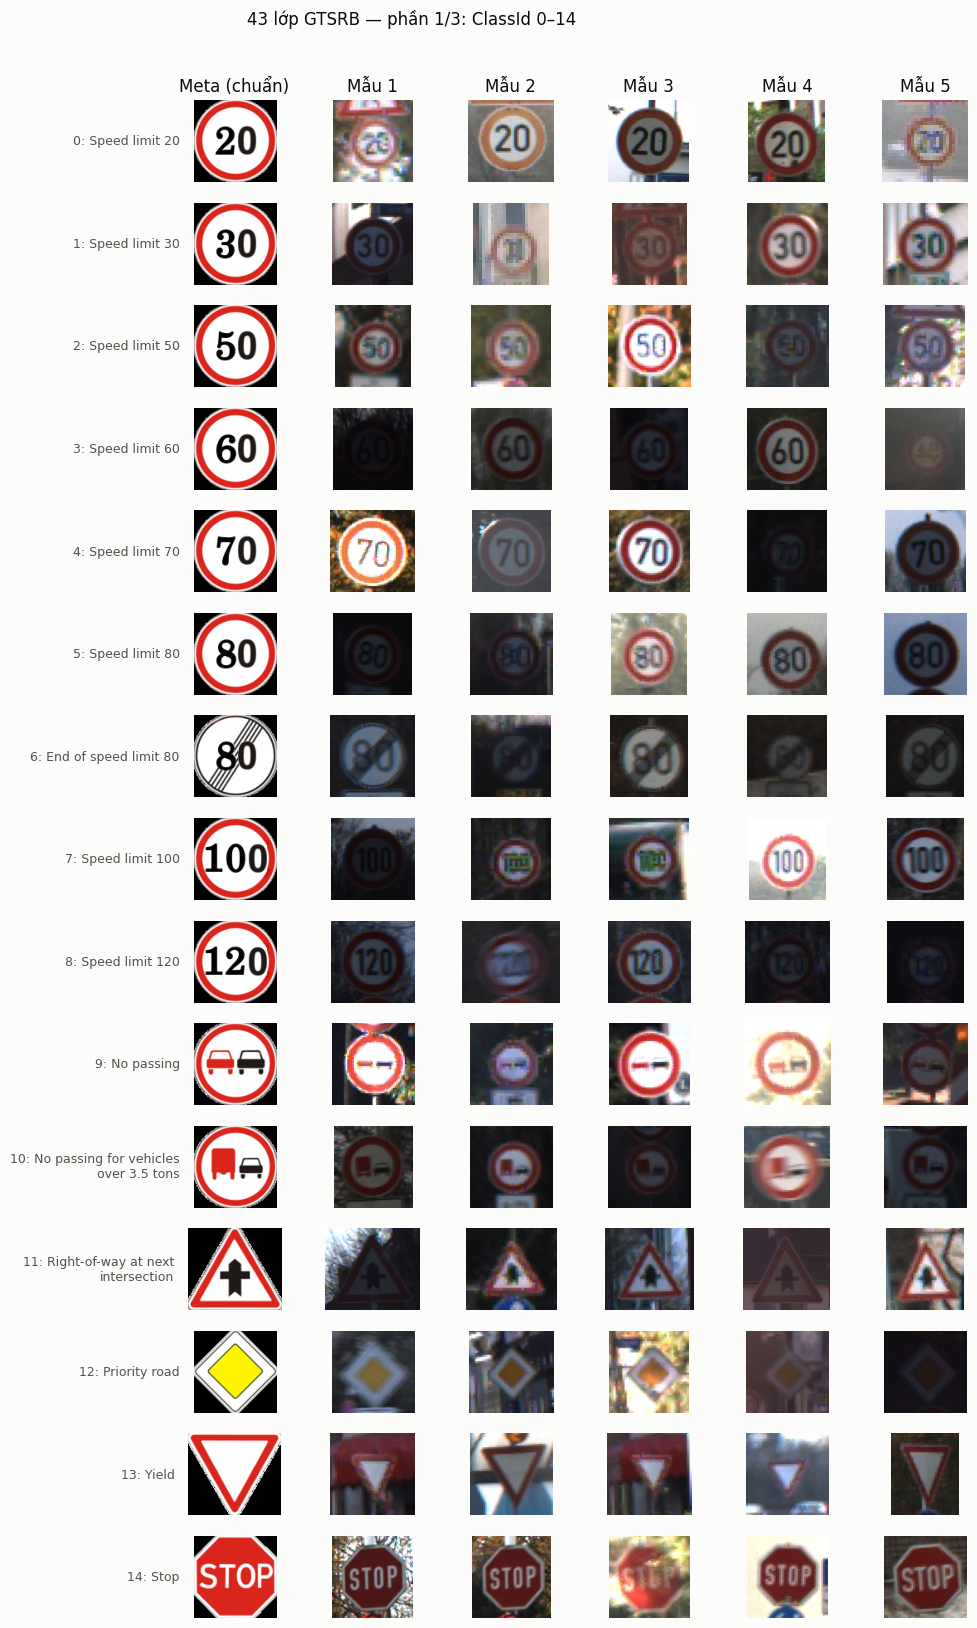

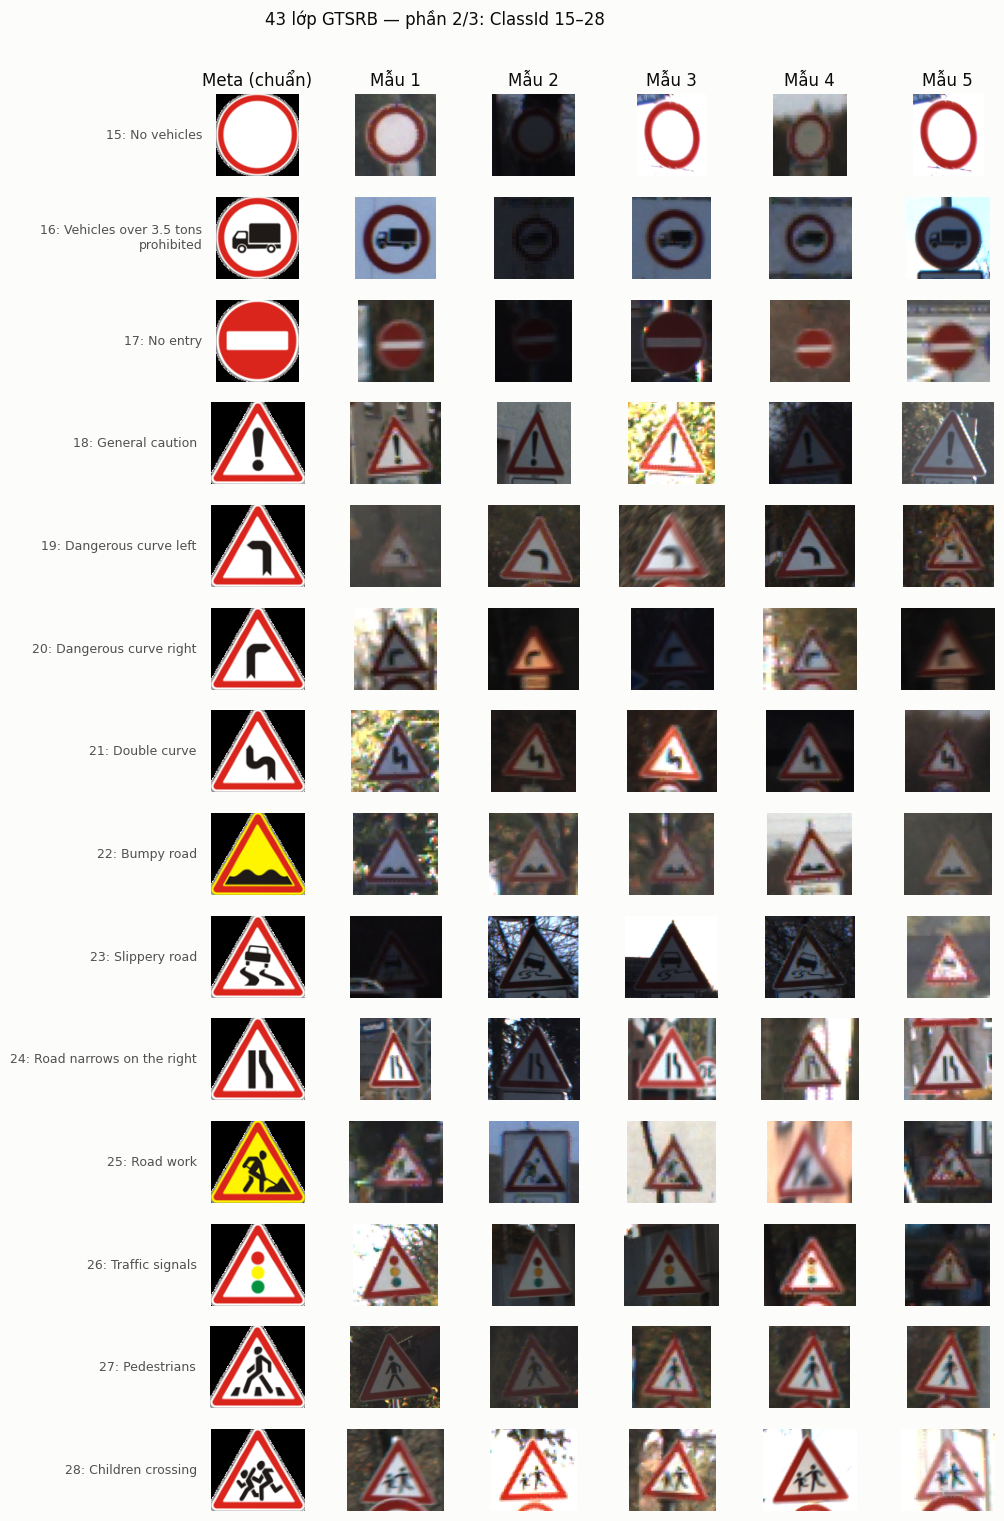

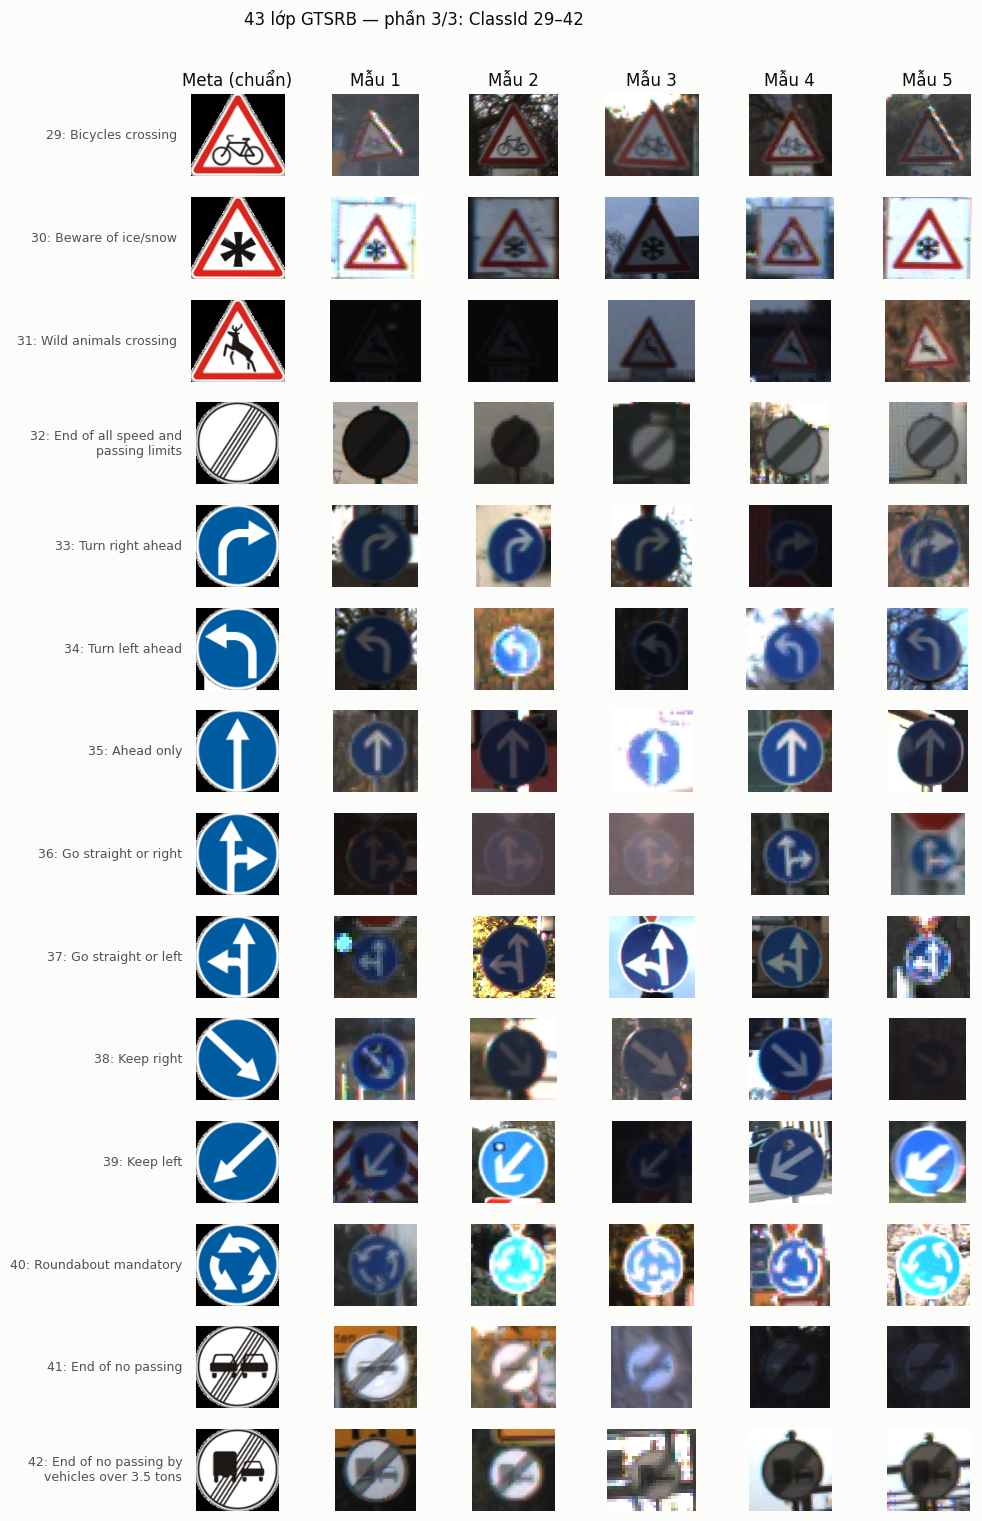

Đã hiển thị: 215 ảnh train + 43 ảnh chuẩn


In [5]:
meta_index = meta_df.set_index("ClassId")
sample_manifest = []
class_groups = [range(0, 15), range(15, 29), range(29, 43)]
for part, class_ids in enumerate(class_groups, start=1):
    class_ids = list(class_ids)
    fig, axes = plt.subplots(
        len(class_ids), 6, figsize=(12, len(class_ids) * 1.1)
    )
    for row_index, class_id in enumerate(class_ids):
        samples = train_df[train_df.ClassId == class_id].sample(
            n=5, random_state=RANDOM_STATE
        )
        standard = read_rgb(ARCHIVE / meta_index.loc[class_id, "Path"])
        images = [standard] + [
            read_rgb(ARCHIVE / path) for path in samples.Path
        ]
        for column, image in enumerate(images):
            ax = axes[row_index, column]
            ax.imshow(image)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            if row_index == 0:
                ax.set_title(
                    "Meta (chuẩn)" if column == 0 else f"Mẫu {column}"
                )
        axes[row_index, 0].set_ylabel(
            f"{class_id}: "
            + textwrap.fill(CLASS_NAMES[class_id], width=25),
            rotation=0, ha="right", va="center", fontsize=9, labelpad=10,
        )
        for path in samples.Path:
            sample_manifest.append({"ClassId": class_id, "Path": path})
    fig.suptitle(
        f"43 lớp GTSRB — phần {part}/3: "
        f"ClassId {class_ids[0]}–{class_ids[-1]}",
        y=0.995,
    )
    fig.subplots_adjust(
        left=0.3, right=0.98, top=0.94, bottom=0.02,
        hspace=0.25, wspace=0.1,
    )
    filename = (
        "eda_samples_grid.png"
        if part == 1 else f"eda_samples_grid_{part}.png"
    )
    save_figure(fig, filename)
save_table(pd.DataFrame(sample_manifest), "eda_samples_manifest.csv")
print("Đã hiển thị:", len(sample_manifest), "ảnh train + 43 ảnh chuẩn")

**NHẬN XÉT:** Lưới gồm **215 ảnh train và 43 ảnh chuẩn** trên 3 hình.
Ảnh cùng lớp có thể rất khác nhau về nền, độ sáng và góc nhìn; ảnh Meta sạch
không phản ánh độ khó ngoài thực tế. Các lớp giới hạn tốc độ có cùng hình tròn
và viền đỏ, khác chủ yếu ở chữ số nhỏ; màu không đủ để phân biệt toàn bộ 43 lớp.

## 5. Chất lượng ảnh và diện tích ROI
**MỤC ĐÍCH:** Đo độ sáng (trung bình grayscale) và tương phản (độ lệch chuẩn
 grayscale) của **2.000 ảnh train gốc lấy mẫu phân tầng**. Đây là thống kê mẫu,
không tuyên bố cực trị của toàn dữ liệu. Diện tích ROI được tính trên mọi dòng CSV,
bao gồm cận X2/Y2, giống cách crop trong tiền xử lý.

,brightness,contrast
count,2000.000000,2000.000000
mean,0.318157,0.163798
std,0.184354,0.095256
min,0.034063,0.009927
25%,0.170438,0.079892
50%,0.290640,0.159415
75%,0.441859,0.237452
max,0.953873,0.422850


,Train,Test
count,39209.000000,12630.000000
mean,0.595767,0.593376
std,0.092043,0.092821
min,0.351166,0.351166
25%,0.521236,0.516602
50%,0.603427,0.600625
75%,0.687433,0.686768
max,0.755393,0.738525


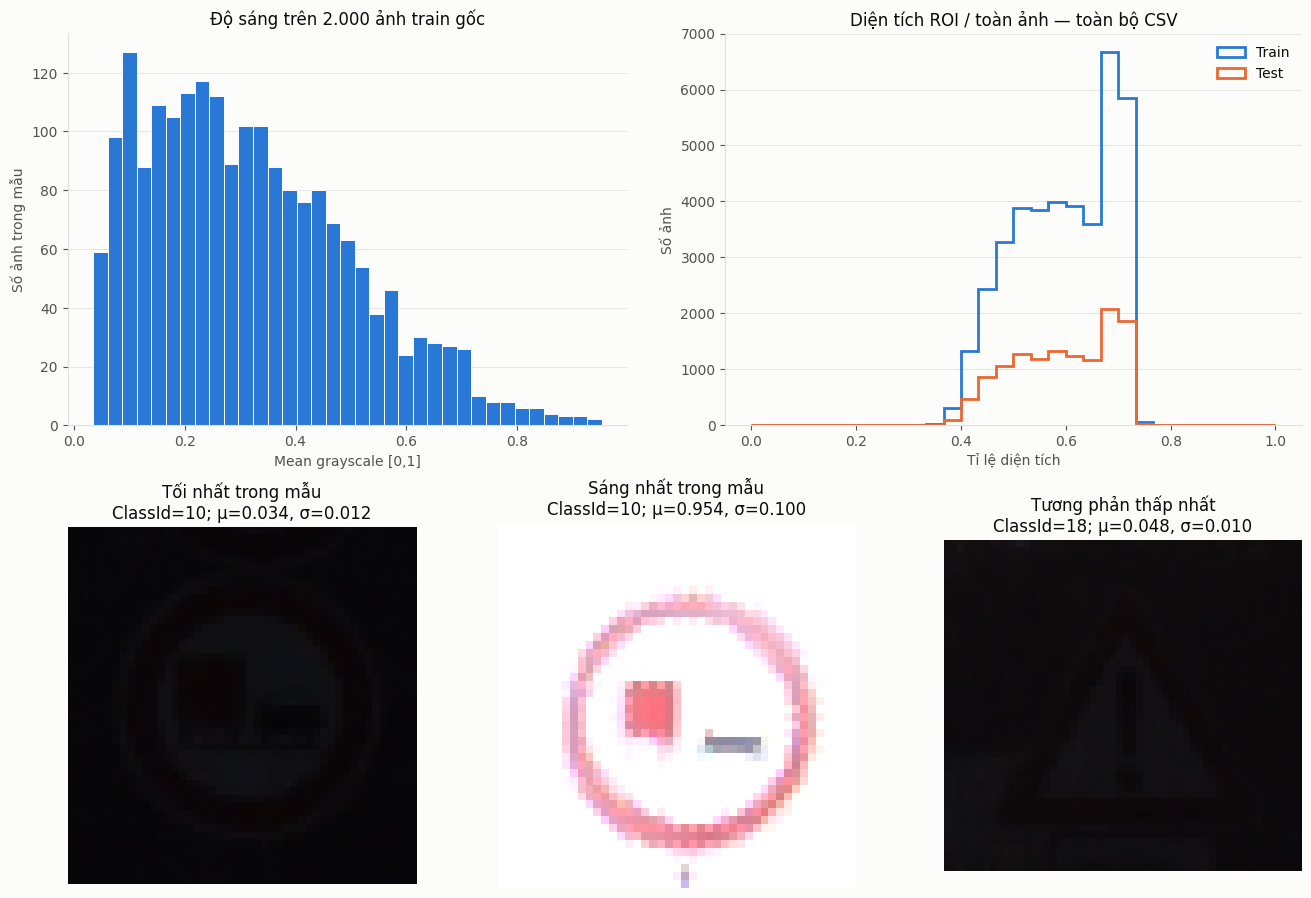

In [6]:
quality_indices = stratified_indices(train_df.ClassId.to_numpy(), 2000)
quality_df = train_df.iloc[quality_indices].copy()
quality_rows = []
for _, row in quality_df.iterrows():
    image = read_rgb(ARCHIVE / row.Path)
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0
    roi_image = crop_roi(image, row[list(ROI_COLUMNS)].to_numpy())
    means = roi_image.mean(axis=(0, 1)) / 255.0
    quality_rows.append(
        {
            "Path": row.Path,
            "ClassId": int(row.ClassId),
            "brightness": float(gray.mean()),
            "contrast": float(gray.std()),
            "R": means[0],
            "G": means[1],
            "B": means[2],
        }
    )
quality = pd.DataFrame(quality_rows)
roi_tables = {}
for split in ("Train", "Test"):
    frame = frames[split]
    x1 = frame["Roi.X1"].clip(lower=0)
    y1 = frame["Roi.Y1"].clip(lower=0)
    x2 = np.minimum(frame["Roi.X2"], frame.Width - 1)
    y2 = np.minimum(frame["Roi.Y2"], frame.Height - 1)
    roi_width = (x2 - x1 + 1).clip(lower=0)
    roi_height = (y2 - y1 + 1).clip(lower=0)
    ratio = (roi_width * roi_height) / (frame.Width * frame.Height)
    roi_tables[split] = pd.DataFrame({"Path": frame.Path, "ROI/ảnh": ratio})
    save_table(roi_tables[split], f"eda_roi_{split.lower()}.csv")
roi_stats = pd.DataFrame(
    {name: frame["ROI/ảnh"].describe() for name, frame in roi_tables.items()}
)
display(quality[["brightness", "contrast"]].describe())
display(roi_stats)

extremes = [
    quality.brightness.idxmin(),
    quality.brightness.idxmax(),
    quality.contrast.idxmin(),
]
fig = plt.figure(figsize=(13, 9), layout="constrained")
grid = fig.add_gridspec(2, 6)
brightness_ax = fig.add_subplot(grid[0, :3])
brightness_ax.hist(
    quality.brightness,
    bins=35,
    color=COLORS["Train"],
    edgecolor=SURFACE,
    linewidth=0.7,
)
brightness_ax.set(
    title="Độ sáng trên 2.000 ảnh train gốc",
    xlabel="Mean grayscale [0,1]",
    ylabel="Số ảnh trong mẫu",
)
brightness_ax.grid(axis="y")
roi_ax = fig.add_subplot(grid[0, 3:])
for split in ("Train", "Test"):
    roi_ax.hist(
        roi_tables[split]["ROI/ảnh"],
        bins=np.linspace(0, 1, 31),
        histtype="step",
        linewidth=2,
        color=COLORS[split],
        label=split,
    )
roi_ax.set(
    title="Diện tích ROI / toàn ảnh — toàn bộ CSV",
    xlabel="Tỉ lệ diện tích",
    ylabel="Số ảnh",
)
roi_ax.legend()
roi_ax.grid(axis="y")
for index, (row_id, title) in enumerate(
    zip(
        extremes,
        ("Tối nhất trong mẫu", "Sáng nhất trong mẫu", "Tương phản thấp nhất"),
    )
):
    row = quality.loc[row_id]
    ax = fig.add_subplot(grid[1, index * 2 : index * 2 + 2])
    ax.imshow(read_rgb(ARCHIVE / row.Path))
    ax.set_title(
        f"{title}\nClassId={row.ClassId}; μ={row.brightness:.3f}, σ={row.contrast:.3f}"
    )
    ax.axis("off")
save_figure(fig, "eda_quality.png")
save_table(quality, "eda_quality_sample.csv")
save_table(roi_stats, "eda_roi_statistics.csv")
summary["quality"] = {
    "sample_size": len(quality),
    "brightness": quality.brightness.describe().to_dict(),
    "contrast": quality.contrast.describe().to_dict(),
    "roi_train_median": float(roi_stats.loc["50%", "Train"]),
    "roi_test_median": float(roi_stats.loc["50%", "Test"]),
}

**NHẬN XÉT:** Trên **2.000 ảnh train gốc**, độ sáng trung bình là **0,3182**, trung vị
**0,2906**, phạm vi **0,0341–0,9539**. Tương phản (std grayscale) trung vị **0,1594**,
nhỏ nhất **0,0099**. Đây là cực trị trong mẫu, không phải toàn bộ 39.209 ảnh.
Diện tích ROI/toàn ảnh có trung vị **60,34% ở train** và **60,06% ở test**.

Độ sáng/tương phản đo trên ảnh gốc; trung bình R/G/B ở mục sau đo trên ROI,
không trộn lẫn hai định nghĩa. Ảnh tối hoặc ít tương phản làm mất cạnh và chữ số.
Chia 255 chỉ đổi thang số, **không** sửa phơi sáng, mờ hay tương phản thấp.

## 6. Màu sắc có quan trọng không?
**MỤC ĐÍCH:** Ghép ColorId/ShapeId từ Meta theo ClassId, thống kê mean RGB của ROI
trên mẫu 2.000 ảnh; không coi các pixel trong cùng một ảnh là mẫu độc lập.
So sánh **KNN k=3, uniform, Euclidean** trên cùng **5.000 ảnh train** và
**2.000 ảnh thuộc test chính thức**, lấy mẫu phân tầng với `RANDOM_STATE`.
Grayscale dùng độ chói OpenCV, giữ một kênh; cả hai đều chia 255, không scaler/PCA.

**Giới hạn đánh giá:** Theo yêu cầu, đây là thí nghiệm EDA trên test con; đã xem test
để so sánh nên không được gọi phần test đã xem là holdout hoàn toàn chưa đụng tới.
Không tuning k hay tăng điểm bằng cách thử nhiều cấu hình. Muốn chốt lựa chọn độc lập,
thành viên 3 cần kiểm tra lại bằng cross-validation theo track trên train.

Số lớp theo ColorId × ShapeId:


ShapeId,0,1,2,3,4
ColorId,,,,,
0,15,13,0,1,1
1,0,8,0,0,0
2,0,0,1,0,0
3,0,4,0,0,0


R                         G                         B  \
             mean       std count      mean       std count      mean   
ColorId                                                                 
0        0.360884  0.213989  1549  0.304244  0.179694  1549  0.309470   
1        0.294762  0.153053   287  0.339328  0.177080   287  0.439858   
2        0.388287  0.202822   107  0.362161  0.189887   107  0.344783   
3        0.284949  0.175445    57  0.282083  0.168851    57  0.284113   

                         
              std count  
ColorId                  
0        0.171670  1549  
1        0.217414   287  
2        0.170905   107  
3        0.160094    57

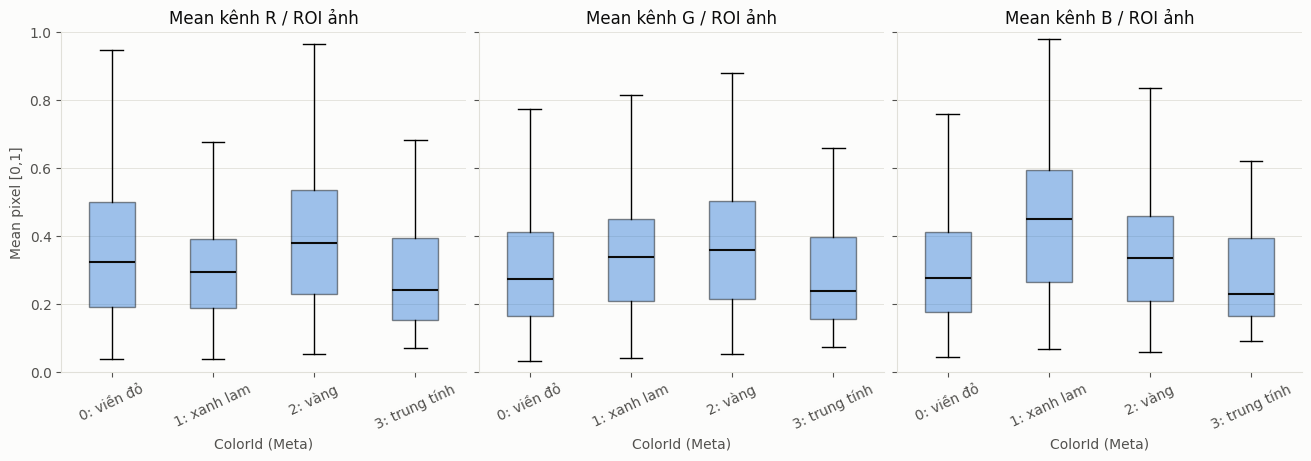

2026-11-11 22:26:16 INFO [MainThread] Bắt đầu load_and_preprocess: seed=42 IMAGE_SIZE=(32, 32) USE_ROI=True USE_CACHE=True


2026-11-11 22:26:20 INFO [MainThread] cache=hit file=cache/gtsrb_32.npz


2026-11-11 22:26:20 INFO [MainThread] Train: X shape=(39209, 32, 32, 3) dtype=float32 min=0.000000 max=1.000000; y shape=(39209,) dtype=int64 min=0 max=42 classes=43


2026-11-11 22:26:20 INFO [MainThread] Test: X shape=(12630, 32, 32, 3) dtype=float32 min=0.000000 max=1.000000; y shape=(12630,) dtype=int64 min=0 max=42 classes=43


2026-11-11 22:26:20 INFO [MainThread] Hoàn tất load_and_preprocess: Train=39209 Test=12630 class_names=43 errors=0 skipped=0 elapsed=4.063s


,Số chiều,Accuracy,Macro-F1,Thời gian (s)
Biểu diễn,,,,
RGB,3072,0.4295,0.369129,1.274551
Grayscale,1024,0.4035,0.343802,0.361081


117981

In [7]:
color_sample = quality.merge(
    meta_df[["ClassId", "ColorId", "ShapeId"]],
    on="ClassId",
    how="left",
    validate="many_to_one",
)
assert not color_sample[["ColorId", "ShapeId"]].isna().any().any()
print("Số lớp theo ColorId × ShapeId:")
color_shape = pd.crosstab(meta_df.ColorId, meta_df.ShapeId)
display(color_shape)
color_stats = color_sample.groupby("ColorId")[["R", "G", "B"]].agg(
    ["mean", "std", "count"]
)
display(color_stats)
# Tên nhóm màu được đối chiếu trực quan ảnh Meta; mã ID vẫn là khóa chính.
color_labels = {
    0: "0: viền đỏ",
    1: "1: xanh lam",
    2: "2: vàng",
    3: "3: trung tính",
}
fig, axes = plt.subplots(
    1, 3, figsize=(13, 4.5), sharey=True, layout="constrained"
)
for ax, channel in zip(axes, ("R", "G", "B")):
    group_ids = sorted(color_sample.ColorId.unique())
    values = [
        color_sample.loc[color_sample.ColorId == group, channel]
        for group in group_ids
    ]
    ax.boxplot(
        values,
        showfliers=False,
        patch_artist=True,
        boxprops={"facecolor": COLORS["Train"], "alpha": 0.45},
        medianprops={"color": INK, "linewidth": 1.5},
    )
    ax.set_xticks(
        range(1, len(group_ids) + 1),
        [color_labels[group] for group in group_ids],
    )
    ax.set_title(f"Mean kênh {channel} / ROI ảnh")
    ax.set_xlabel("ColorId (Meta)")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y")
axes[0].set(ylabel="Mean pixel [0,1]", ylim=(0, 1))
save_figure(fig, "eda_color.png")
save_table(color_stats, "eda_color_statistics.csv")
save_table(color_shape, "eda_color_shape.csv")

# Nạp một lần để dùng lại ở mục 8; không sao chép toàn bộ tập khi chỉ lấy mẫu.
X_train_img, X_test_img, y_train, y_test, class_names = load_and_preprocess(
    str(ROOT / DATA_DIR)
)
train_indices = stratified_indices(y_train, 5000)
test_indices = stratified_indices(y_test, 2000)
assert len(np.unique(y_train[train_indices])) == 43
assert len(np.unique(y_test[test_indices])) == 43
rgb_train, rgb_test = X_train_img[train_indices], X_test_img[test_indices]
gray_train, gray_test = to_grayscale(rgb_train), to_grayscale(rgb_test)
knn_rows = []
for representation, train_images, test_images in (
    ("RGB", rgb_train, rgb_test),
    ("Grayscale", gray_train, gray_test),
):
    started = time.perf_counter()
    knn = KNeighborsClassifier(
        n_neighbors=3,
        weights="uniform",
        metric="euclidean",
        algorithm="brute",
        n_jobs=1,
    )
    # Giới hạn luồng để notebook không chiếm toàn bộ máy khi nhân ma trận.
    with threadpool_limits(limits=2):
        knn.fit(
            train_images.reshape(len(train_images), -1), y_train[train_indices]
        )
        predictions = knn.predict(test_images.reshape(len(test_images), -1))
    knn_rows.append(
        {
            "Biểu diễn": representation,
            "Số chiều": int(np.prod(train_images.shape[1:])),
            "Accuracy": accuracy_score(y_test[test_indices], predictions),
            "Macro-F1": f1_score(
                y_test[test_indices],
                predictions,
                average="macro",
                labels=np.arange(43),
                zero_division=0,
            ),
            "Thời gian (s)": time.perf_counter() - started,
        }
    )
knn_results = pd.DataFrame(knn_rows).set_index("Biểu diễn")
display(knn_results)
save_table(knn_results, "eda_knn_color_comparison.csv")
manifest = pd.concat(
    [
        pd.DataFrame(
            {
                "Split": "Train",
                "Path": train_df.iloc[train_indices].Path,
                "ClassId": y_train[train_indices],
            }
        ),
        pd.DataFrame(
            {
                "Split": "Test",
                "Path": test_df.iloc[test_indices].Path,
                "ClassId": y_test[test_indices],
            }
        ),
    ],
    ignore_index=True,
)
save_table(manifest, "eda_knn_sample_manifest.csv")
summary["knn"] = {
    "train_size": len(train_indices),
    "test_size": len(test_indices),
    "results": knn_results.to_dict(orient="index"),
}
del rgb_train, rgb_test, gray_train, gray_test, train_images, test_images, knn
gc.collect()

**NHẬN XÉT — kết quả KNN k=3, 5.000 train / 2.000 test, seed 42:**

| Biểu diễn | Số chiều | Accuracy | Macro-F1 |
|---|---:|---:|---:|
| RGB | 3.072 | **42,95%** | **36,91%** |
| Grayscale | 1.024 | 40,35% | 34,38% |

RGB cao hơn **2,60 điểm phần trăm Accuracy** và **2,53 điểm phần trăm Macro-F1**.
**Quyết định: giữ RGB**, vừa bảo toàn màu vừa phù hợp hợp đồng HOG ba kênh.
Không khẳng định RGB luôn thắng mọi mô hình: điểm baseline còn thấp,
chưa có kiểm định nhiều seed hay khoảng tin cậy, và chỉ đánh giá test con.

ColorId/ShapeId mô tả nhóm biển chứ không thay thế ClassId; nhóm trung tính
vẫn có sai lệch R/G/B do chiếu sáng và bối cảnh. RGB có 3.072 chiều trong khi
grayscale có 1.024 chiều, nên phép so sánh vừa thay thông tin màu vừa thay hình học
khoảng cách; đây là baseline thăm dò, không phải ablation hoàn hảo.
**Test con đã được xem trong EDA**: không dùng nó để tuning tiếp và cần xác nhận
lựa chọn bằng CV theo track trên train trước khi chốt mô hình.

## 7. Before/After và augmentation hợp lệ
**MỤC ĐÍCH:** Minh họa đúng chuỗi xử lý: ảnh RGB gốc → crop ROI → resize 32×32 uint8
→ float32/255. Dùng cùng mẫu, cùng seed để minh họa riêng xoay, dịch, đổi sáng/
tương phản và tổ hợp nhẹ. Đây chỉ là minh họa; không thêm ảnh vào train/test mặc định.

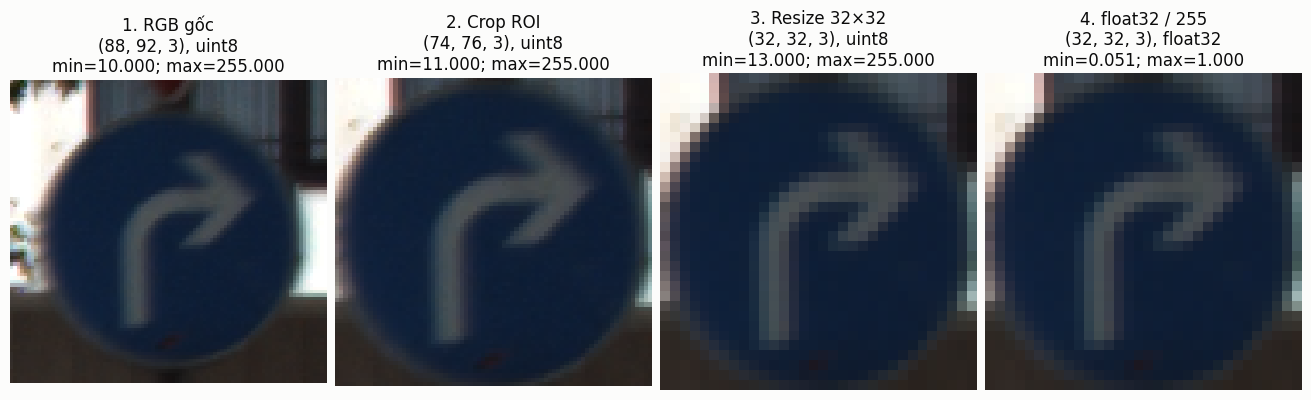

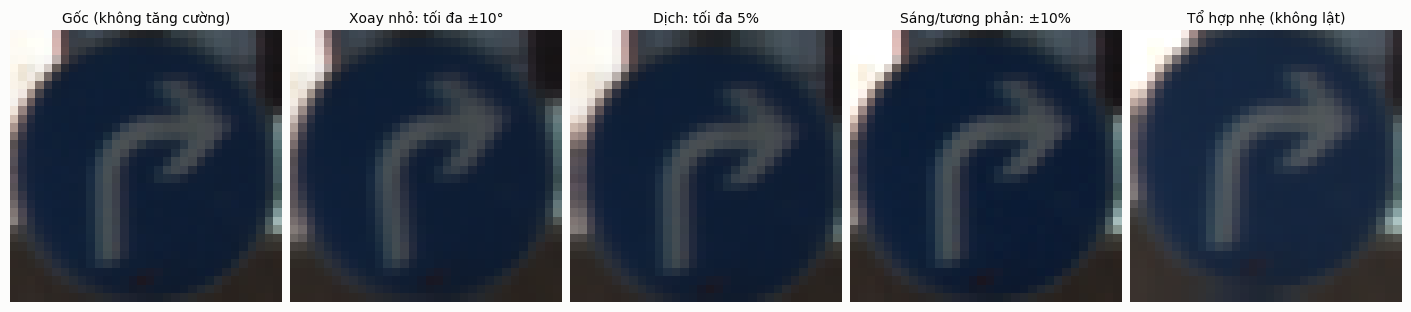

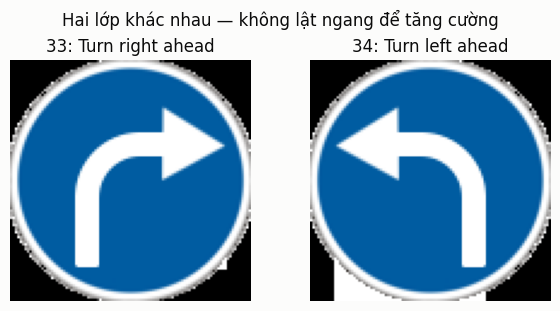

In [8]:
example = (
    train_df[train_df.ClassId == 33]
    .sample(n=1, random_state=RANDOM_STATE)
    .iloc[0]
)
original = read_rgb(ARCHIVE / example.Path)
cropped = crop_roi(original, example[list(ROI_COLUMNS)].to_numpy())
resized = cv2.resize(cropped, IMAGE_SIZE, interpolation=cv2.INTER_AREA)
normalized = load_image(
    ARCHIVE / example.Path, example[list(ROI_COLUMNS)].to_numpy()
)
fig, axes = plt.subplots(1, 4, figsize=(13, 4), layout="constrained")
for ax, image, title in zip(
    axes,
    (original, cropped, resized, normalized),
    ("1. RGB gốc", "2. Crop ROI", "3. Resize 32×32", "4. float32 / 255"),
):
    ax.imshow(image, interpolation="nearest")
    ax.set_title(
        f"{title}\n{image.shape}, {image.dtype}\n"
        f"min={image.min():.3f}; max={image.max():.3f}"
    )
    ax.axis("off")
save_figure(fig, "eda_before_after.png")

rng_aug = np.random.default_rng(RANDOM_STATE)
variants = [
    ("Gốc (không tăng cường)", normalized),
    (
        "Xoay nhỏ: tối đa ±10°",
        augment_image(
            normalized,
            enabled=True,
            rng=rng_aug,
            max_shift=0,
            brightness=0,
            contrast=0,
        ),
    ),
    (
        "Dịch: tối đa 5%",
        augment_image(
            normalized,
            enabled=True,
            rng=rng_aug,
            max_rotation=0,
            brightness=0,
            contrast=0,
        ),
    ),
    (
        "Sáng/tương phản: ±10%",
        augment_image(
            normalized, enabled=True, rng=rng_aug, max_rotation=0, max_shift=0
        ),
    ),
    (
        "Tổ hợp nhẹ (không lật)",
        augment_image(normalized, enabled=True, rng=rng_aug),
    ),
]
fig, axes = plt.subplots(
    1, len(variants), figsize=(14, 3.5), layout="constrained"
)
for ax, (title, image) in zip(axes, variants):
    ax.imshow(image, interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
save_figure(fig, "eda_augmentation.png")
# Đối chiếu hai biển thật, KHÔNG tạo ảnh lật hoặc gán lại nhãn.
fig, axes = plt.subplots(1, 2, figsize=(6, 3), layout="constrained")
for ax, class_id in zip(axes, (33, 34)):
    ax.imshow(read_rgb(ARCHIVE / meta_index.loc[class_id, "Path"]))
    ax.set_title(f"{class_id}: {CLASS_NAMES[class_id]}")
    ax.axis("off")
fig.suptitle("Hai lớp khác nhau — không lật ngang để tăng cường")
save_figure(fig, "eda_forbidden_flip_classes.png")

**NHẬN XÉT:** Hai ảnh cuối trông giống nhau vì `imshow` hiểu thang uint8 [0,255]
và float [0,1]; chia 255 không phải tăng sáng hay chuẩn hóa mean/std.

**CẤM lật ngang/dọc:** `Turn right ahead` **33 ↔ 34** `Turn left ahead`,
`Keep right` **38 ↔ 39** `Keep left` có thể đổi nhãn khi phản chiếu.
Hình bổ sung chỉ đặt hai ảnh Meta thật cạnh nhau, **không thực hiện phép lật**.
Augmentation xoay/dịch/ánh sáng cũng chỉ nên áp dụng cho train và kiểm tra bằng mắt;
không có biến đổi nào bảo đảm mọi ảnh chất lượng thấp đều còn đủ thông tin.

## 8. Kiểm tra hợp đồng đầu ra và mean images
**MỤC ĐÍCH:** Gọi lại `load_and_preprocess` để kiểm chứng đường nạp cache trên toàn bộ
dữ liệu; giải phóng batch ở mục 6 trước khi nạp lại. Đối chiếu thứ tự nhãn với CSV
và một ảnh với hàm đọc RGB. Kiểm tra theo khối để không tạo mảng boolean hàng trăm MB.
Vẽ mean image các lớp giới hạn tốc độ để gợi ý phân tích confusion matrix
cho Thành viên 4.

2026-11-11 22:26:24 INFO [MainThread] Bắt đầu load_and_preprocess: seed=42 IMAGE_SIZE=(32, 32) USE_ROI=True USE_CACHE=True


2026-11-11 22:26:28 INFO [MainThread] cache=hit file=cache/gtsrb_32.npz


2026-11-11 22:26:29 INFO [MainThread] Train: X shape=(39209, 32, 32, 3) dtype=float32 min=0.000000 max=1.000000; y shape=(39209,) dtype=int64 min=0 max=42 classes=43


2026-11-11 22:26:29 INFO [MainThread] Test: X shape=(12630, 32, 32, 3) dtype=float32 min=0.000000 max=1.000000; y shape=(12630,) dtype=int64 min=0 max=42 classes=43


2026-11-11 22:26:29 INFO [MainThread] Hoàn tất load_and_preprocess: Train=39209 Test=12630 class_names=43 errors=0 skipped=0 elapsed=4.186s


,shape,dtype,min,max,Số lớp
Tập,,,,,
Train,"(39209, 32, 32, 3)",float32,0.0,1.0,43
Test,"(12630, 32, 32, 3)",float32,0.0,1.0,43


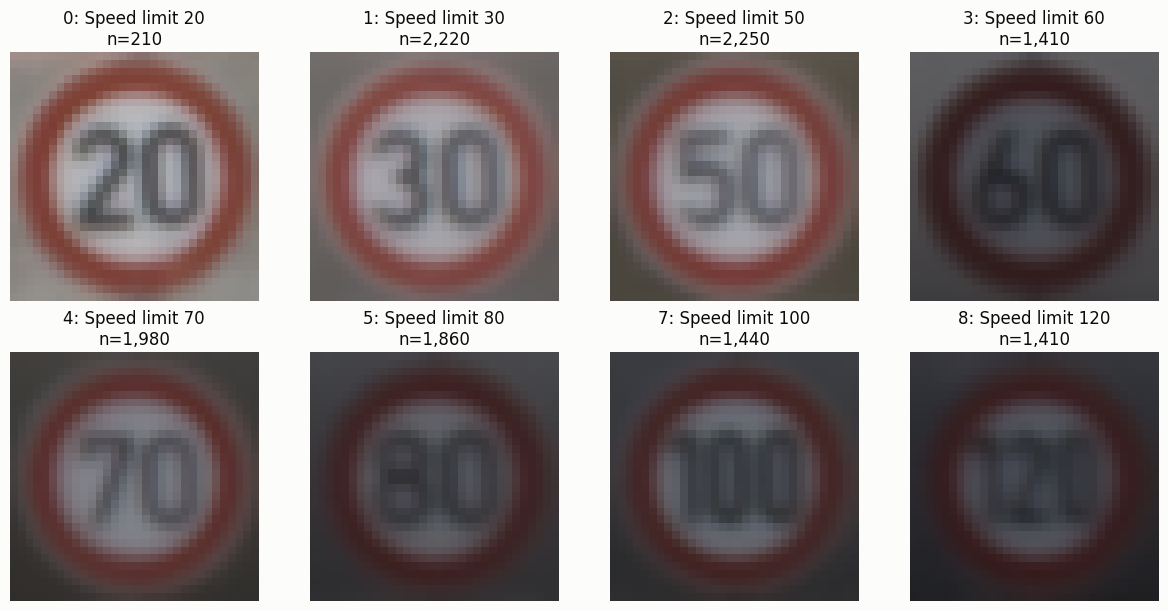

Đạt hợp đồng. Đã lưu 11 hình PNG, dpi=150.
Số liệu: report/eda_summary.json; bảng: report/tables/


In [9]:
# Nạp lại từ hàm công khai để kiểm tra đường cache sau thí nghiệm.
# Giải phóng batch cũ trước, tránh giữ hai bản ~600 MB cùng lúc.
del X_train_img, X_test_img, y_train, y_test
gc.collect()
X_train_img, X_test_img, y_train, y_test, class_names = load_and_preprocess(
    str(ROOT / DATA_DIR)
)
assert isinstance(class_names, list) and len(class_names) == 43
assert class_names == CLASS_NAMES
contract_rows = []
for split, images, labels, frame in (
    ("Train", X_train_img, y_train, train_df),
    ("Test", X_test_img, y_test, test_df),
):
    assert isinstance(images, np.ndarray) and images.ndim == 4
    assert images.shape == (len(frame), 32, 32, 3)
    assert images.dtype == np.float32
    assert labels.ndim == 1 and labels.shape == (len(frame),)
    assert np.issubdtype(labels.dtype, np.integer)
    assert set(np.unique(labels)) == set(range(43))
    np.testing.assert_array_equal(labels, frame.ClassId.to_numpy())
    for start in range(0, len(images), 1024):
        chunk = images[start : start + 1024]
        assert np.isfinite(chunk).all()
        assert 0 <= chunk.min() <= chunk.max() <= 1
    first_row = frame.iloc[0]
    np.testing.assert_array_equal(
        images[0],
        load_image(
            ARCHIVE / first_row.Path, first_row[list(ROI_COLUMNS)].to_numpy()
        ),
    )
    contract_rows.append(
        {
            "Tập": split,
            "shape": str(images.shape),
            "dtype": str(images.dtype),
            "min": float(images.min()),
            "max": float(images.max()),
            "Số lớp": len(np.unique(labels)),
        }
    )
contract = pd.DataFrame(contract_rows).set_index("Tập")
display(contract)
save_table(contract, "eda_contract.csv")

speed_ids = [0, 1, 2, 3, 4, 5, 7, 8]
fig, axes = plt.subplots(2, 4, figsize=(12, 6), layout="constrained")
for ax, class_id in zip(axes.flat, speed_ids):
    indices = np.flatnonzero(y_train == class_id)
    mean_image = X_train_img[indices].mean(axis=0)
    ax.imshow(mean_image)
    ax.set_title(f"{class_id}: {CLASS_NAMES[class_id]}\nn={len(indices):,}")
    ax.axis("off")
save_figure(fig, "eda_mean_images.png")
summary["contract"] = contract.to_dict(orient="index")
summary["figures"] = saved_figures
summary["limitations"] = [
    "KNN chỉ thăm dò trên 5.000 train / 2.000 test, không tuning.",
    "Test con đã dùng cho EDA; cần xác nhận bằng CV theo track trên train.",
    "Không kiểm tra trùng nội dung bằng hash toàn bộ ảnh.",
    "ROI có sẵn giả định đầu vào đã định vị biển, không phải detection.",
    "Resize vuông có thể méo ảnh/mất chi tiết; không sửa mờ, phơi sáng.",
    "Cache kiểm tra CSV/cấu hình, không băm ảnh; sửa ảnh cần tạo lại cache.",
]
with (ROOT / "report" / "eda_summary.json").open(
    "w", encoding="utf-8"
) as stream:
    json.dump(summary, stream, ensure_ascii=False, indent=2)
print(f"Đạt hợp đồng. Đã lưu {len(saved_figures)} hình PNG, dpi=150.")
print("Số liệu: report/eda_summary.json; bảng: report/tables/")

**NHẬN XÉT:** Hợp đồng phải đạt: train **(39209,32,32,3)**, test
**(12630,32,32,3)**, float32 RGB trong [0,1], y nguyên 1D và 43 tên lớp đúng chỉ số.
Mean images của **20/30/50/60/70/80/100/120** có viền đỏ và bố cục rất giống nhau;
trung bình ảnh còn làm nhòe chữ số. Đây là **giả thuyết lớp khó**, không phải kết quả
confusion matrix;